#
**<h1 align="center">LAB Report: Interpolation</h1>**

<div align="right">
  <strong>Name: Rushabhkumar Bharti</strong><br>
  <strong>SC Code: SC26M0015</strong>
</div>

---



## **Module Import**

In [21]:
# do not change line below
# from google.colab import files

import numpy as np                      # for maths
import matplotlib.pyplot as plt         # For Plots

## **Problem Statement:**

*   Construct a smooth **NACA-abcd** Airfoil surface using NACA Airfoil Equation
*   Reconstruct the same Airfoil using Lagrange Interpolation.
*   Plot both the Airfoil and Compare the plots.
*   Calculate Max error and RMS Error between actual Airfoil.
*   How to improve Errors?
*   Reconstruct the airfoil using cubic splines and quantify the errors.







## **1: NACA MPTT Airfoil Equation**

The NACA airfoil series is a set of airfoil shapes developed by the National Advisory Committee for Aeronautics (NACA). The shape of a NACA airfoil is described using a series of digits following the word "NACA".

#### Four-Digit Series (NACA MPTT)

For a NACA four-digit airfoil, the digits define the following:

*   **M**: Maximum camber (first digit) as a percentage of the chord (0.01 = 1%)
*   **P**: Position of the maximum camber (second digit) in tenths of the chord (0.05 = 50% of the chord)
*   **TT**: Maximum thickness (third and fourth digits) as a percentage of the chord (0.12 = 12% of the chord)

The **camber line** ($y_c$) is given by:
<h3 align="center">$ y_c = \begin{cases} \frac{m}{p^2}(2px - x^2) & 0 \le x \le pc \\ \frac{m}{(1-p)^2}((1-2p)c + 2px - x^2) & pc < x \le c \end{cases} $</h3>



Where:
*   $x$ is the position along the chord
*   $c$ is the chord length (typically normalized to 1)
*   $m$ is the maximum camber as a fraction of the chord
*   $p$ is the position of the maximum camber as a fraction of the chord

The **half-thickness distribution** ($y_t$) is given by:

<h3 align="center">$$y_t = \frac{t}{0.2} (0.2969\sqrt{x} - 0.1260x - 0.3516x^2 + 0.2843x^3 - 0.1036x^4)$$</h3>



Where:
*   $t$ is the maximum thickness as a fraction of the chord

The **angle of the camber line** ($\theta$) is given by:

<h3 align="center">$$ \frac{dy_c}{dx} = \begin{cases} \frac{2m}{p^2}(p-x) & 0 \le x \le pc \\ \frac{2m}{(1-p)^2}(p-x) & pc < x \le c \end{cases} $$
$$ \theta = \arctan\left(\frac{dy_c}{dx}\right) $$</h3>





Finally, the **coordinates of the upper surface** $(x_u, y_u)$ and **lower surface** $(x_l, y_l)$ are:

<h4 align="center">$$x_u = x - y_t \sin(\theta)$$</h4>
<h4 align="center">$$y_u = y_c + y_t \cos(\theta)$$</h4>
<h4 align="center">$$x_l = x + y_t \sin(\theta)$$</h4>
<h4 align="center">$$y_l = y_c - y_t \cos(\theta)$$</h4>















> [**REF**](https://en.wikipedia.org/wiki/NACA_airfoil)




In [22]:
class Airfoil():
    def __init__(self, m, p, t):
        self.m = m
        self.p = p
        self.t = t
        self.name = f"NACA {int(100*m)}{int(10*p)}{int(100*t)}"

    def camber(self, x):
        m = self.m
        p = self.p
        y_c = np.where(x <= p,
                    m/p**2*(2*p*x - x**2),
                    m/(1 - p)**2*((1-2*p) + 2*p*x - x**2))
        return y_c

    def half_thickness(self, x):
        y_t = 5*self.t*(0.2969*np.sqrt(x) - 0.126*x - 0.3516*x**2 + 0.2843*x**3 - 0.1036*x**4)
        return y_t

    def theta(self, x):
        m = self.m
        p = self.p
        dy_dx = np.where(x <= p, 2*m/p**2*(p-x), 2*m/(1-p)**2*(p-x))
        return np.arctan(dy_dx)

    def generate_airfoil(self, x):
        y_t = self.half_thickness(x)
        y_c = self.camber(x)
        theta = self.theta(x)

        x_u = x - y_t*np.sin(theta)
        y_u = y_c + y_t*np.cos(theta)

        x_l = x + y_t*np.sin(theta)
        y_l = y_c - y_t*np.cos(theta)

        return y_c, x_u, y_u, x_l, y_l

In [23]:
np.random.seed(20)
m = np.random.randint(2, 5)/100
p = np.random.randint(3, 6)/10
t = np.random.randint(10, 26)/100

airfoil = Airfoil(m, p, t)

In [24]:
eval_inp = np.linspace(0, 1, 500)
y_c, x_u, y_u, x_l, y_l = airfoil.generate_airfoil(eval_inp)

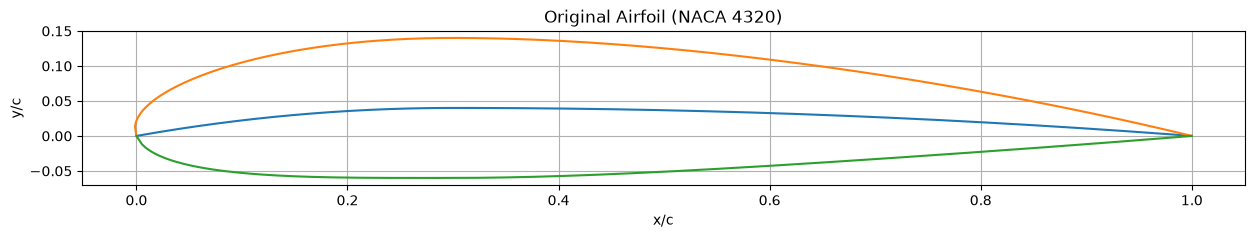

In [25]:
plt.figure(figsize=(15, 2))
plt.plot(eval_inp, y_c)
plt.plot(x_u, y_u)
plt.plot(x_l, y_l)
plt.grid(True)
plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title(f"Original Airfoil ({airfoil.name})")
plt.show()

## **2: Lagrange Interpolation**

Lagrange interpolation is a method for interpolating a polynomial that passes through a given set of data points. For a given set of $n+1$ data points $(x_0, y_0), (x_1, y_1), ..., (x_n, y_n)$, where no two $x_i$ are the same, the Lagrange interpolation polynomial $L(x)$ of degree at most $n$ is given by:

<h3 align="center">$$L(x) = \sum_{j=0}^{n} y_j L_j(x)$$</h3>


Where $L_j(x)$ are the Lagrange basis polynomials, defined as:

<h3 align="center">$$L_j(x) = \prod_{k=0, k \neq j}^{n} \frac{x - x_k}{x_j - x_k}$$</h3>


This polynomial has the property that $L_j(x_j) = 1$ and $L_j(x_k) = 0$ for $k \neq j$, ensuring that $L(x_i) = y_i$ for all given data points.


> [**REF**](https://www.google.com/search?q=lagrange+Interpolation&sourceid=chrome&ie=UTF-8&amc=1&gs_lcrp=EgZjaHJvbWUyBggAEEUYOTINCAEQABiABBjwBRieBjINCAIQABiABBjwBRieBjIQCAMQABiABBjwBRieBhi0BzINCAQQABiABBjwBRieBjINCAUQABiABBjwBRieBtIBCTgxMDFqMGozMagCA7ACAeoHCggBEAAYACAAKAA&oq=lagrange+Interpolation&udm=50&aep=42&cud=0&source=chrome.crn.rb&mstk=AUtExfCQY6gq0gNIG55fhaFH1UYMKiljdm3Fzz3kJjISkItd0zvOted2M9vCMt9Dr8iA3vvGxlF21L_JkLOEhn_fRAoEKyQPginPaNo6GIwNWINzfLGWDFJtKgePEgDLq9qgssPaIZjf_4NJLKxTKf-inhNPTOa3EIGTBIuVdiWGUrwKojJKdI1s6IvXzltomRAxOfKAv5lEFW74vtc9iI7u6ah_Kcj9rlUTgxIBZ3oUDo1hdNIEPGxyxs_9bA&csuir=1&atvm=2)



In [26]:
def Lagrange(x, y, xx):
    n = len(x)
    result = np.zeros_like(xx, dtype=float)
    for i in range(n):
        pd = 1
        for j in range(len(x)):
            if j!=i:
                pd *= (xx - x[j])/(x[i] - x[j])
        result += y[i]*pd
    return result

In [27]:
train_inp = np.linspace(0, 1, 15)
_ , x_u_train, y_u_train, x_l_train, y_l_train = airfoil.generate_airfoil(train_inp)

In [28]:
y_u_interp = Lagrange(x_u_train, y_u_train, x_u)
y_l_interp = Lagrange(x_l_train, y_l_train, x_l)

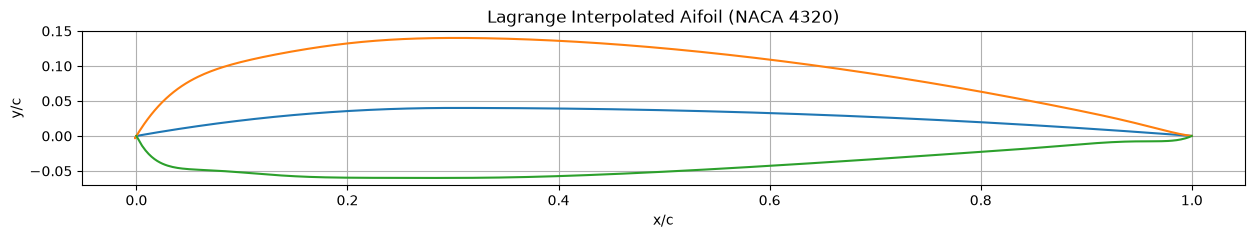

In [29]:
plt.figure(figsize=(15, 2))
plt.plot(eval_inp, y_c)
plt.plot(x_u, y_u_interp)
plt.plot(x_l, y_l_interp)
plt.grid(True)
plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title(f"Lagrange Interpolated Aifoil ({airfoil.name})")
plt.show()

## **3: Comparing the both the Plots**
        
> Poor approximation near leading edge is due to the fact that leading edge has more curvature and it requires more sample points near leading edge to correctly capture the curvature.





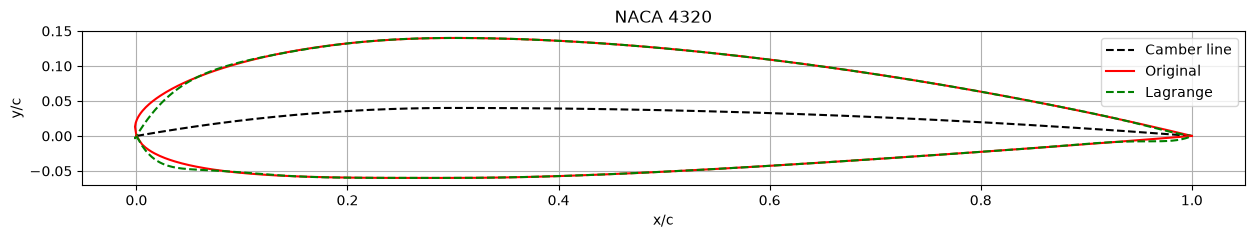

In [30]:
plt.figure(figsize=(15, 2))

plt.plot(eval_inp, y_c, "k--", label="Camber line")

plt.plot(x_u, y_u, "r", label="Original")
plt.plot(x_u, y_u_interp, "g--", label="Lagrange")

plt.plot(x_l, y_l, "r")
plt.plot(x_l, y_l_interp, "g--")

plt.grid(True)
plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title(airfoil.name)
plt.legend()
plt.show()

## **4: Error Determination**

##### **1: MAX Error**

<h2 align="center">$$\text{Max Error} = \max_{i=1}^{n} |y_i - \hat{y}_i|$$</h2>  



In [31]:
# calculate MAX error
err_u = np.max(np.abs(y_u - y_u_interp))
err_l = np.max(np.abs(y_l - y_l_interp))
print(f"MAX error in upper surface: {err_u}")
print(f"MAX error in lower surface: {err_l}")

MAX error in upper surface: 0.023082748970932536
MAX error in lower surface: 0.009502145299299547


#####**2: RMS Error**

<h2 align="center">$RMSE = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2}$</h2>  



In [32]:
# calculate RMS error
adj = np.concatenate((y_u - y_u_interp, y_l - y_l_interp))
rms_err = np.sqrt(np.mean(adj**2))
print(f"RMS error: {rms_err}")

RMS error: 0.0029060083483990365


## **Parametric Variation: N vs RMS**
    N: No of Data Points
    RMS: RMS error at different Data Points

In [33]:
N = np.array([5, 8, 11, 14, 17, 20, 23])
RMS = np.zeros_like(N, dtype=float)
for idx, n in enumerate(N):
    train_inp = np.linspace(0, 1, n)
    _ , x_u_train, y_u_train, x_l_train, y_l_train = airfoil.generate_airfoil(train_inp)

    eval_inp = np.linspace(0, 1, 100)
    y_c, x_u, y_u, x_l, y_l = airfoil.generate_airfoil(eval_inp)

    y_u_interp = Lagrange(x_u_train, y_u_train, x_u)
    y_l_interp = Lagrange(x_l_train, y_l_train, x_l)

    # calculate RMS error
    adj = np.concatenate((y_u - y_u_interp, y_l - y_l_interp))
    rms_error = np.sqrt(np.mean(adj**2))
    RMS[idx] = rms_error

print(f"Calculated RMS values: {RMS}")

Calculated RMS values: [0.00848936 0.00441424 0.00300081 0.00240286 0.00192074 0.00503515
 0.02704626]


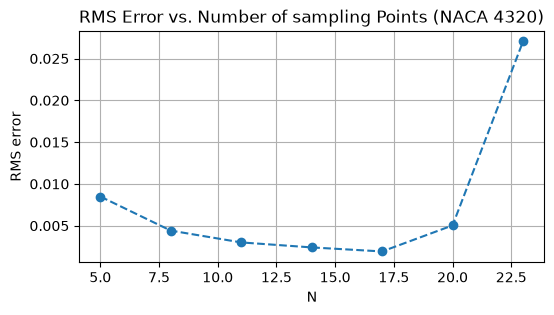

In [34]:
plt.figure(figsize=(6, 3))
plt.plot(N, RMS, "o--")
plt.grid(True)
plt.xlabel("N")
plt.ylabel("RMS error")
plt.title(f"RMS Error vs. Number of sampling Points ({airfoil.name})")
plt.show()

## **6: Cubic Spline Interpolation**

Cubic spline interpolation is a numerical method used to estimate values between known data points by fitting a series of cubic polynomials between consecutive points.

Suppose we are given $n+1$ data points:

$$(x_0, y_0), (x_1, y_1), \dots, (x_n, y_n)$$

Between every pair of consecutive points, we define a cubic polynomial:

$$S_i(x) = a_i + b_i(x-x_i) + c_i(x-x_i)^2 + d_i(x-x_i)^3$$

where $S_i(x)$ is the polynomial on the interval $[x_i, x_{i+1}]$.

### **Conditions for a Cubic Spline**

* **Condition 1: The spline passes through the data points.**
  $$S_i(x_i) = y_i, \quad S_i(x_{i+1}) = y_{i+1}$$

* **Condition 2: The first derivatives are continuous.**
  $$S'_{i-1}(x_i) = S'_i(x_i)$$

* **Condition 3: The second derivatives are continuous.**
  $$S''_{i-1}(x_i) = S''_i(x_i)$$

* **Condition 4: Natural boundary conditions are required.**
  $$S''(x_0) = 0, \quad S''(x_n) = 0$$

---

### **Alternate Way (Matrix Construction)**

There is a more convenient way to construct a cubic spline in Python using equations for the second derivatives.

Let:
$$h_i = x_{i+1} - x_i$$

$$M_i = S''(x_i)$$

Here, $h_i$ is the width of an interval, and $M_i$ is the second derivative at a knot (data point). For each interior point ($i = 1, 2, \dots, n-1$), the natural cubic spline equations are:

$$h_{i-1}M_{i-1} + 2(h_{i-1} + h_i)M_i + h_iM_{i+1} = 6\left[\frac{y_{i+1} - y_{i}}{h_i} - \frac{y_{i} - y_{i-1}}{h_{i-1}}\right]$$

For a natural spline, the boundary conditions are:

$$M_0 = 0, \quad M_n = 0$$

Once the second derivatives ($M_i$) are known, the cubic polynomial on the interval $[x_i, x_{i+1}]$ is given by:

$$S_i(x) = \frac{M_i(x_{i+1} - x)^3}{6h_i} + \frac{M_{i+1}(x - x_i)^3}{6h_i} + \left(\frac{y_i}{h_i} - \frac{M_i h_i}{6}\right)(x_{i+1} - x) + \left(\frac{y_{i+1}}{h_i} - \frac{M_{i+1} h_i}{6}\right)(x - x_i)$$


> [**REF**](https://chatgpt.com/uc/6ad21e49-5b20-83ea-a437-97dbe73bf859)

In [35]:
def cubic_spline(x, y, x_target):

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x_target = np.asarray(x_target, dtype=float)

    n = len(x)

    # Interval widths
    h = np.diff(x)

    # Construct the system for the second derivatives
    A = np.zeros((n - 2, n - 2))
    b = np.zeros(n - 2)

    for i in range(1, n - 1):
        row = i - 1

        A[row, row] = 2 * (h[i - 1] + h[i])

        if i > 1:
            A[row, row - 1] = h[i - 1]

        if i < n - 2:
            A[row, row + 1] = h[i]

        b[row] = 6 * (
            (y[i + 1] - y[i]) / h[i]
            - (y[i] - y[i - 1]) / h[i - 1]
        )

    # Natural boundary conditions:
    # M[0] = M[n-1] = 0
    M = np.zeros(n)
    M[1:n - 1] = np.linalg.solve(A, b)

    # Find the interval for every x_target
    i = np.searchsorted(x, x_target, side="right") - 1

    # If x_target == x[-1], use the last interval
    i = np.minimum(i, n - 2)

    # Distance from interval endpoints
    h_i = h[i]
    x_left = x[i]
    x_right = x[i + 1]

    # Cubic spline interpolation formula
    result = (
        M[i] * (x_right - x_target) ** 3 / (6 * h_i)
        + M[i + 1] * (x_target - x_left) ** 3 / (6 * h_i)
        + (y[i] / h_i - M[i] * h_i / 6)
          * (x_right - x_target)
        + (y[i + 1] / h_i - M[i + 1] * h_i / 6)
          * (x_target - x_left)
    )

    return result

In [36]:
x = [1, 2, 5, 11]
y = [4, 6, 25, 20]

y_u_interp_CSP = cubic_spline(x_u_train, y_u_train, x_u)
y_l_interp_CSP = cubic_spline(x_l_train, y_l_train, x_l)

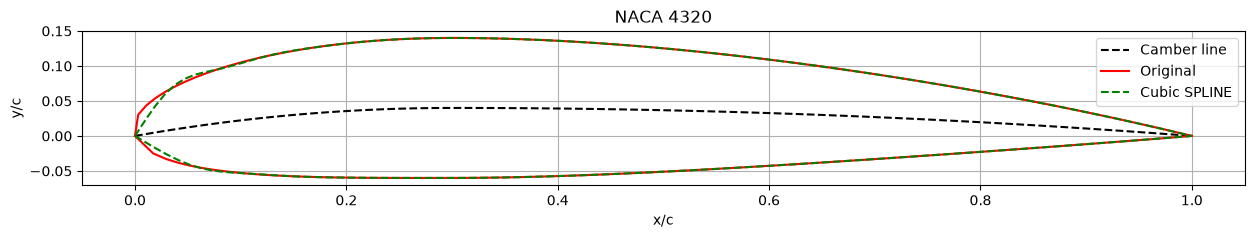

In [37]:
plt.figure(figsize=(15, 2))

plt.plot(eval_inp, y_c, "k--", label="Camber line")

plt.plot(x_u, y_u, "r", label="Original")
plt.plot(x_u, y_u_interp_CSP, "g--", label="Cubic SPLINE")

plt.plot(x_l, y_l, "r")
plt.plot(x_l, y_l_interp_CSP, "g--")

plt.grid(True)
plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title(airfoil.name)
plt.legend()
plt.show()

### **Error Determination**


##### **1: MAX Error**

In [38]:
# calculate MAX error
error_u = np.max(np.abs(y_u - y_u_interp_CSP))
error_l = np.max(np.abs(y_l - y_l_interp_CSP))
print(f"MAX error in upper surface: {error_u}")
print(f"MAX error in lower surface: {error_l}")

MAX error in upper surface: 0.023320321770939154
MAX error in lower surface: 0.00934063857552531


##### **2: RMS Error**

In [39]:
# calculate RMS error
adj = np.concatenate((y_u - y_u_interp_CSP, y_l - y_l_interp_CSP))
rms_error = np.sqrt(np.mean(adj**2))
print(f"RMS error: {rms_error}")

RMS error: 0.0024894161866233218


## **Result and Discussion**

### **1. Performance Summary & Error Metrics**



| Error Metric | Lagrange Interpolation | Cubic Spline Interpolation |
| :--- | :---: | :---: |
| **MAX Error (Upper Surface)** | 0.0231 | 0.0233 |
| **MAX Error (Lower Surface)** | 0.0095 | 0.0093 |
| **RMS Error (Overall)** | \$\mathbf{0.0029}$ | 0.0025 |

---


### **2. Key Technical Observations & Insights**

* **The Leading Edge Challenge (High Curvature):**
  Both interpolation techniques show their maximum error near the **leading edge** (x/c ≈ 0.0 to 0.2). This happens because the airfoil has a very sharp curve in this region. Standard uniform sampling struggle to perfectly capture such rapid geometry changes.
  
* **Lagrange vs. Cubic Spline Performance:**
  For this specific 15-point distribution (`train_inp = np.linspace(0, 1, 15)`), **Cubic Spline Interpolation achieved a slightly lower RMS error (0.0025)** compared to Lagrange (0.0029).

* **The Edge of Cubic Splines (Smoothness over Runge's Phenomenon):**
  While Lagrange performed mathematically closer to the test points here, it is prone to massive oscillations (Runge's Phenomenon) if we increase the number of knots (n). The **Cubic Spline** plot maintains a much more physically realistic and physically smooth curve, making it safer for aerodynamic modeling.

---

### **3. Strategic Recommendations for Improvement**

To significantly minimize the errors and bring the approximation closer to the true NACA 4320 geometry, we can implement the following strategies:

1. **Non-Uniform/Clustered Sampling (Chebyshev Nodes):**
   Instead of using a simple linear space (`np.linspace`), we should use **denser sampling near the leading edge** (e.g., Cosine clustering or Chebyshev nodes). Adding more data points where the curvature is high will drastically drop the MAX error.
   
2. **Boundary Condition Tuning:**
   Switching from a **Natural Spline** ($M_0=0$, $M_n=0$) to a **Clamped Spline** (where we feed the actual exact slopes $dy/dx$ at the boundaries) will force the spline to perfectly match the true aerodynamic profile at the start and end points.


## **Conclusion**
*   Both the interpolation Technique correctly approximate the Airfoil curve along most of the airfoil surface with negligible error. But Leading edge has more cuvature as compare to Trailing Edge ,therefore both the Interpolation technique poorly approximate the curve near Leading edge.
